# Bonus B1: How to make a LangGraph workflow survive a restart

**Notebook 1 of 2: meet the checkpoint file on a permission slip**

## Goal

Write a small job that has to wait for a person: a school-trip permission slip that goes home on Friday and comes
back on Monday. We keep the waiting job in a file, restart the kernel so that nothing of our program is left in
memory, find the slip still waiting, and send the parent's answer. Then we look at what the resume ran a second
time, and change the graph so that it does not. This notebook is the playground; notebook 2 takes the same idea
to a refund at the Chinook support desk.

## What you will learn

- How to write a job that waits for a person as a LangGraph graph: a state, nodes, edges and `interrupt`.
- How to keep a paused run in a file with `SqliteSaver`, and find it again by its thread id.
- How to open the checkpoint file as an ordinary SQLite file and read what it holds.
- How to resume a paused run in a new Python process, after a kernel restart.
- Why the code before `interrupt` runs again on a resume, and how a node of its own prevents that.

⚠️ **This notebook asks you to restart the kernel once, in Part D.** Run the cells one at a time, in order. If you
choose **Run All**, the notebook stops at the restart with a message that says what to do.

## Setup

No model is called in this notebook, so it needs no API key. The setup imports LangGraph and names the folder and
the file we will write to. `outputs/` is a folder that git ignores.

In [1]:
import sqlite3
from pathlib import Path
from typing_extensions import TypedDict

from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

OUTPUTS = Path("outputs")
OUTPUTS.mkdir(exist_ok=True)
TRIP_FILE = OUTPUTS / "trip.db"

print("checkpoint file:", TRIP_FILE)

checkpoint file: outputs/trip.db


---

## Part A: Write a job that waits for a person as a graph

A class is going to the science museum. On Friday the teacher sends a permission slip home with each child. The
parent answers on Monday, and only then is a seat on the bus booked.

The job has a long wait in the middle. A plain Python function can wait too, for example with `input()`, but its
place in the job is kept in the memory of the running program. If the program stops over the weekend, the job is
gone. LangGraph keeps the job outside the program. For that it needs the job in pieces it can save:

- a **state**: a dictionary with everything the job has collected so far;
- **nodes**: the steps. A node is a Python function that takes the state and returns only the keys it adds;
- **edges**: which node runs after which.

We start with the state. One slip looks like this:

In [2]:
slip = {"child": "Maya", "trip": "the science museum"}

print(slip)

{'child': 'Maya', 'trip': 'the science museum'}


Two keys now, and a third one later: `allowed`, the parent's answer. A `TypedDict` names the keys the state may
hold. It is a description for LangGraph and for the reader; it checks nothing while the program runs.

The second step of the job is the simpler one, so we write it first. `book_seat` reads the answer and prints what
it did. It adds nothing to the state, so it returns an empty dictionary. A node is plain Python, so we can call
it by hand with a slip that already has an answer.

In [3]:
class Slip(TypedDict):
    child: str
    trip: str
    allowed: bool


def book_seat(slip):
    if slip["allowed"]:
        print("SEAT BOOKED for", slip["child"])
    else:
        print("NO SEAT for", slip["child"])
    return {}


update = book_seat({"child": "Maya", "trip": "the science museum", "allowed": True})

print("returned:", update)

SEAT BOOKED for Maya
returned: {}


The function printed `SEAT BOOKED for Maya` and returned `{}`. The print stands for the real work, booking the
seat. We will watch for that line for the rest of the notebook.

### A node that stops and waits

The first step sends the slip home and waits for the answer. The waiting is one call, `interrupt(...)`:

- `interrupt(question)` stops the run at that line and hands `question` to the code that started the graph.
- When the run is continued later with an answer, `interrupt(...)` returns that answer and the node carries on.

Our node `ask_parent` has three lines. The first prints `SLIP SENT HOME`, which stands for handing the slip to
the child. The second waits. The third turns the answer into `True` or `False` and returns it under `allowed`.

In [4]:
def ask_parent(slip):
    print("SLIP SENT HOME with", slip["child"])
    answer = interrupt(f"May {slip['child']} go to {slip['trip']}?")
    return {"allowed": answer == "yes"}

We do not call this one by hand: `interrupt` only works inside a graph that is running.

### Wire the two nodes into a graph

- `StateGraph(Slip)` starts a graph whose state has the keys of `Slip`.
- `add_node(name, function)` adds a step.
- `add_edge(a, b)` says that `b` runs after `a`. `START` and `END` are where a run enters and leaves.

In [5]:
builder = StateGraph(Slip)

builder.add_node("ask_parent", ask_parent)
builder.add_node("book_seat", book_seat)

builder.add_edge(START, "ask_parent")
builder.add_edge("ask_parent", "book_seat")
builder.add_edge("book_seat", END)

print(list(builder.nodes))

['ask_parent', 'book_seat']


The builder holds our two nodes. `compile()` checks the wiring and returns the graph object we can run, and
`draw_mermaid_png()` draws it.

The drawing needs the internet: LangGraph sends the node names and the arrows (none of our data) to
[mermaid.ink](https://mermaid.ink), a public drawing service. If the cell fails, see Troubleshooting. Every other
cell works without it.

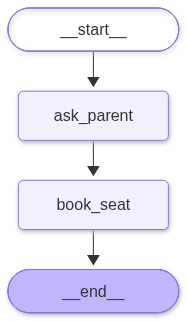

In [6]:
from IPython.display import Image

Image(builder.compile().get_graph().draw_mermaid_png())

A straight line: `__start__`, `ask_parent`, `book_seat`, `__end__`. The drawing does not show the wait. The wait
is inside `ask_parent`, at its second line.

**Checkpoint A.** `book_seat`, called by hand, prints `SEAT BOOKED for Maya` and returns `{}`. The builder lists
the nodes `ask_parent` and `book_seat`, and the drawing shows them in one line between `__start__` and `__end__`.

---

## Part B: Pause the run and keep it in a file

A run that stops has to be kept somewhere until the answer comes. LangGraph needs two things for that.

- A **checkpointer** saves the state after every step. `SqliteSaver` is a checkpointer that saves into a SQLite
  file, here `outputs/trip.db`.
- A **thread id** is a name for one run, so that the checkpointer can tell Maya's slip from every other slip. It
  travels in a `config` dictionary that we pass with every call. `configurable` is the key under which LangGraph
  looks for it.

Two details in the cell:

- The first lines delete the file left by an earlier run of this notebook, and the working files SQLite keeps
  beside it, so that every run starts with an empty file.
- `check_same_thread=False` is an argument of Python's `sqlite3.connect`. It is about Python's threads, which
  have nothing to do with our thread id. LangGraph does part of its saving on a background thread, and this
  argument lets it use the connection there.

In [7]:
for old_file in OUTPUTS.glob("trip.db*"):
    old_file.unlink()

saver = SqliteSaver(sqlite3.connect(TRIP_FILE, check_same_thread=False))
graph = builder.compile(checkpointer=saver)

config = {"configurable": {"thread_id": "slip-maya"}}

It is Friday. We start the job for Maya with `invoke`: the first argument is the state to start from, the second
is the `config` with the thread id.

In [8]:
paused = graph.invoke({"child": "Maya", "trip": "the science museum"}, config)

print("question: ", paused["__interrupt__"][0].value)
print("next node:", graph.get_state(config).next)

SLIP SENT HOME with Maya
question:  May Maya go to the science museum?
next node: ('ask_parent',)


Three lines, and each says something about where the job stands:

- `SLIP SENT HOME with Maya` was printed by the first line of `ask_parent`. The node started.
- `invoke` came back with a key `__interrupt__`. It holds a list with one `Interrupt` object, and its `.value` is
  what `ask_parent` passed to `interrupt(...)`: the question for the parent.
- `get_state(config)` asks the checkpointer about the thread. `.next` names the node that runs when the thread
  continues. It says `ask_parent`, the node that is waiting, and not `book_seat`: `ask_parent` has not finished.
  `.next` is a tuple, because a graph can have more than one node waiting to run; ours has one.

No `SEAT BOOKED` line: the run stopped before `book_seat`.

**Checkpoint B.** One `SLIP SENT HOME with Maya` line, the question *May Maya go to the science museum?*, and
`next node: ('ask_parent',)`.

---

## Part C: Read the checkpoint file as an ordinary SQLite file

The waiting slip is now in `outputs/trip.db`. It is an ordinary SQLite file, and any SQLite tool can open it. We
open it with Python's `sqlite3`, on a second connection that can only read (`mode=ro`), and ask which tables it
has.

In [9]:
file = sqlite3.connect(f"file:{TRIP_FILE}?mode=ro", uri=True)

print(file.execute("SELECT name FROM sqlite_master WHERE type = 'table'").fetchall())

[('checkpoints',), ('writes',)]


Two tables, both made by `SqliteSaver`: `checkpoints` and `writes`.

`checkpoints` has one row for every state LangGraph saved. We print three of its columns: the thread id, a short
note LangGraph keeps about the checkpoint (`metadata`), and the size in bytes of the saved state (`checkpoint`).
`metadata` is stored as bytes, so we `CAST` it to text.

In [10]:
for row in file.execute("SELECT thread_id, CAST(metadata AS TEXT), length(checkpoint) FROM checkpoints"):
    print(row)

('slip-maya', '{"source": "input", "step": -1, "parents": {}}', 279)
('slip-maya', '{"source": "loop", "step": 0, "parents": {}}', 577)


Two checkpoints, both for the thread `slip-maya`:

- `"step": -1` with `"source": "input"` was saved when our input arrived, before anything ran.
- `"step": 0` was saved when the input had been written into the state. `ask_parent` was the next thing to do.

The last number in each row is the size of the saved state in bytes: 280 and 578 in our run, and yours may
differ. The step 0 row is the larger one: by then the slip's two values are keys of the state, and LangGraph
keeps a version number for each key.

There is no checkpoint for `ask_parent`, because it has not finished. A checkpoint is saved after a step, and
this step stopped in the middle.

The second table, `writes`, holds what each step wrote, one row per value. We print the name of the key
(`channel`) and the saved bytes (`value`).

In [11]:
for row in file.execute("SELECT channel, value FROM writes"):
    print(row)

file.close()

('child', b'\xa4Maya')
('trip', b'\xb2the science museum')
('branch:to:ask_parent', b'')
('__interrupt__', b'\x91\xc7|\x02\x93\xaflanggraph.types\xa9Interrupt\x83\xa5value\xd9"May Maya go to the science museum?\xa2id\xd9 65bb8ced27e525b5159464ead06d2d6e\xafresponse_schema\xc0')


Four rows. Read them by their first column:

- `child` and `trip` are our input. The values are bytes in a compact format called MessagePack: `b'\xa4Maya'` is
  one byte that says *a text of four characters*, then the four characters.
- `branch:to:ask_parent` is LangGraph's own note that `ask_parent` runs next. Its value is empty.
- `__interrupt__` is the waiting question. The bytes are longer, and the sentence *May Maya go to the science
  museum?* can be read inside them.

**What the file holds:** the state, the name of the node that runs next, and the question that is waiting.

**What it does not hold:** our Python. The file has the *name* `ask_parent` and none of its code. It also has no
record of the line at which `ask_parent` stopped. Keep that in mind for Part D.

**Important:** the state is saved as it is. Anyone who can open this file can read Maya's name in it. A
checkpoint file needs the same care as any other file with people's data.

**Checkpoint C.** The tables `checkpoints` and `writes`; two checkpoint rows for `slip-maya`, steps -1 and 0;
four rows in `writes`, with `b'\xa4Maya'` under `child` and the question inside the bytes of `__interrupt__`.

---

## Part D: Restart the kernel and resume from the file

Friday evening. The school's computer is switched off for the weekend. We do the same to this notebook's Python.

### Restart the kernel now

- In VS Code, click **Restart** in the notebook's toolbar.
- In JupyterLab, choose **Kernel → Restart Kernel**.

Then carry on from the next code cell. ⚠️ Do not run the cells above again: Part B's cell deletes the file.

After a restart, Python has none of our variables and none of our functions. The file is all that is left. A
program that starts again runs its code again from the top, and that is what the next cell does. It checks first
that the restart happened (after one, the name `graph` is unknown). Then it repeats the imports, the state, the
two nodes and the wiring from Parts A and B, with a new `SqliteSaver` on the same file. The code is the same,
line for line. Nothing in the cell starts a run.

In [1]:
assert "graph" not in globals(), "Restart the kernel first, then run this cell."

import sqlite3
from pathlib import Path
from typing_extensions import TypedDict

from langgraph.checkpoint.sqlite import SqliteSaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt

TRIP_FILE = Path("outputs") / "trip.db"

class Slip(TypedDict):
    child: str
    trip: str
    allowed: bool


def ask_parent(slip):
    print("SLIP SENT HOME with", slip["child"])
    answer = interrupt(f"May {slip['child']} go to {slip['trip']}?")
    return {"allowed": answer == "yes"}


def book_seat(slip):
    if slip["allowed"]:
        print("SEAT BOOKED for", slip["child"])
    else:
        print("NO SEAT for", slip["child"])
    return {}


builder = StateGraph(Slip)
builder.add_node("ask_parent", ask_parent)
builder.add_node("book_seat", book_seat)
builder.add_edge(START, "ask_parent")
builder.add_edge("ask_parent", "book_seat")
builder.add_edge("book_seat", END)

saver = SqliteSaver(sqlite3.connect(TRIP_FILE, check_same_thread=False))
graph = builder.compile(checkpointer=saver)

config = {"configurable": {"thread_id": "slip-maya"}}

print("built again:", list(graph.get_graph().nodes))

built again: ['__start__', 'ask_parent', 'book_seat', '__end__']


The graph is built again, in a new Python process, and no `SLIP SENT HOME` line was printed: building a graph
runs none of its nodes.

It is Monday. Before we answer, we ask the checkpointer what it has for the thread `slip-maya`.

In [2]:
saved = graph.get_state(config)

print("state:     ", saved.values)
print("next node: ", saved.next)
print("waiting on:", saved.interrupts[0].value)

state:      {'child': 'Maya', 'trip': 'the science museum'}
next node:  ('ask_parent',)
waiting on: May Maya go to the science museum?


The slip is still waiting. We gave the new process only the thread id, `slip-maya`. All three lines came from the
file: the state with the child and the trip, the node that runs next, and in `.interrupts` the question that is
waiting.

Read the thread before you answer, because a resume does not warn you when nothing is waiting on the thread. On a
finished thread it runs nothing and returns the final state. On a thread id that was never used it starts a new
run with an empty state, and `ask_parent` fails at its first line with `KeyError: 'child'`.

The parent says yes. To continue a paused run we call `invoke` again, with `Command(resume=...)` in place of a
state, and the same `config`.

Before you run the cell: which lines will it print?

In [3]:
done = graph.invoke(Command(resume="yes"), config)

print("result:   ", done)
print("next node:", graph.get_state(config).next)

SLIP SENT HOME with Maya
SEAT BOOKED for Maya
result:    {'child': 'Maya', 'trip': 'the science museum', 'allowed': True}
next node: ()


The seat is booked, `allowed` is `True`, and `next` is empty: the job is finished. It survived the weekend.

Now read the first line of the output. **`SLIP SENT HOME with Maya` was printed a second time.** Maya took a
second slip home on Monday.

Part C said why. The file holds the name of the node that runs next and no record of the line where it stopped.
So LangGraph cannot continue `ask_parent` from its second line. It runs the node again from its first line:

1. `ask_parent` starts again, and its first line prints `SLIP SENT HOME`.
2. `interrupt(...)` is called again. This time an answer is waiting for it, so it does not stop. It returns
   `"yes"`.
3. The node returns `{"allowed": True}`, and the run goes on to `book_seat`.

The picture shows the two days side by side.

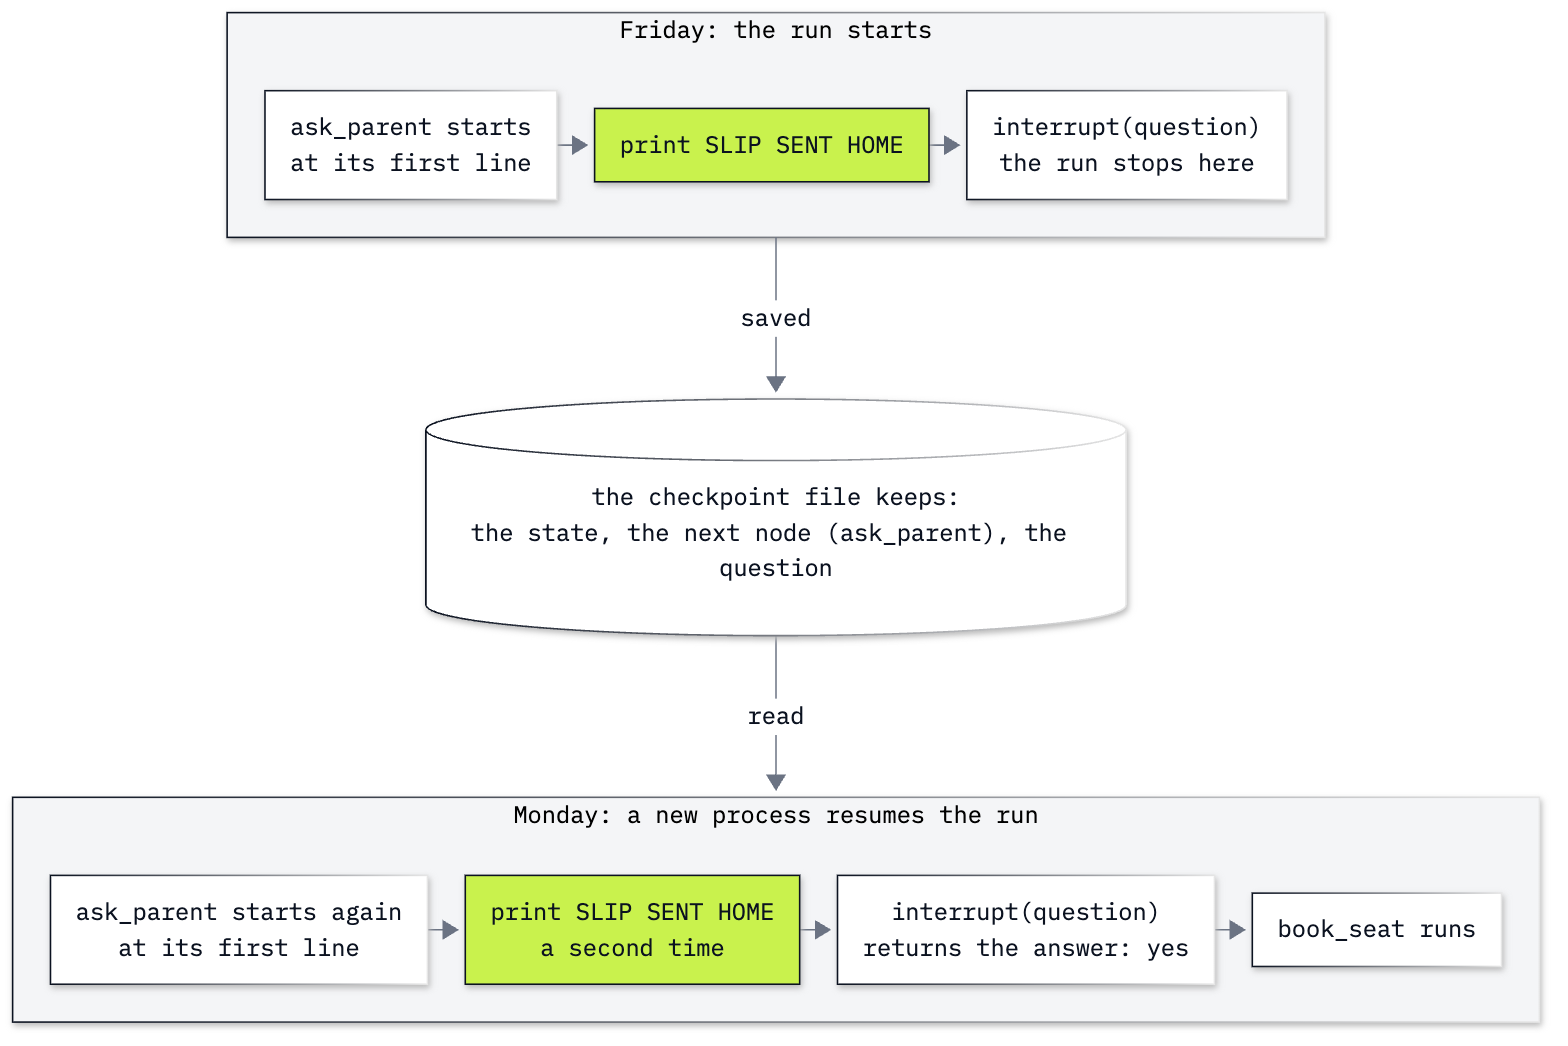

In [4]:
from IPython.display import Image

Image(filename="resources/what_a_resume_runs.png", width=760)

The lime boxes are the line before `interrupt`, which ran on Friday and again on Monday. The white boxes are the
other steps of the run and the checkpoint file.

**Key lesson:** a resume starts the waiting node again from its first line. Every line before `interrupt` runs
once for the pause and once more for the resume. A print does no harm. An email, a payment or a new row in a
table would happen twice.

**Checkpoint D.** After the restart, `get_state` shows Maya's slip with `next node: ('ask_parent',)` and the
question waiting. The resume prints `SLIP SENT HOME with Maya` again, then `SEAT BOOKED for Maya`, and returns
`allowed: True`.

---

## Part E: Keep work that must happen once in a node of its own

The restart did not cause the second slip. Any resume runs the waiting node again from its first line, with or
without a restart. The restart only makes it easy to see why: the new process had the file, and the file does
not say where the node stopped.

What LangGraph does keep is every node that **finished**. It saves a checkpoint after each one, and a finished
node is not run again. So we split `ask_parent` in two:

- `send_slip` sends the slip and finishes;
- `wait_for_parent` only waits. It has no line before `interrupt`.

In [5]:
def send_slip(slip):
    print("SLIP SENT HOME with", slip["child"])
    return {}


def wait_for_parent(slip):
    answer = interrupt(f"May {slip['child']} go to {slip['trip']}?")
    return {"allowed": answer == "yes"}


builder = StateGraph(Slip)

builder.add_node("send_slip", send_slip)
builder.add_node("wait_for_parent", wait_for_parent)
builder.add_node("book_seat", book_seat)

builder.add_edge(START, "send_slip")
builder.add_edge("send_slip", "wait_for_parent")
builder.add_edge("wait_for_parent", "book_seat")
builder.add_edge("book_seat", END)

graph_v2 = builder.compile(checkpointer=saver)

print(list(graph_v2.get_graph().nodes))

['__start__', 'send_slip', 'wait_for_parent', 'book_seat', '__end__']


Three nodes now, on the same checkpointer and the same file. We send a slip home with Leo, on a thread of its
own.

In [6]:
leo = {"configurable": {"thread_id": "slip-leo"}}

paused = graph_v2.invoke({"child": "Leo", "trip": "the science museum"}, leo)

print("question: ", paused["__interrupt__"][0].value)
print("next node:", graph_v2.get_state(leo).next)

SLIP SENT HOME with Leo
question:  May Leo go to the science museum?
next node: ('wait_for_parent',)


One `SLIP SENT HOME with Leo` line, and the thread waits at `wait_for_parent`. `send_slip` has finished.

Leo's parent says yes. We do not restart this time. Count the `SLIP SENT HOME` lines in the output.

In [7]:
done = graph_v2.invoke(Command(resume="yes"), leo)

print("result:", done)

SEAT BOOKED for Leo
result: {'child': 'Leo', 'trip': 'the science museum', 'allowed': True}


None. The resume printed `SEAT BOOKED for Leo` and nothing else. `wait_for_parent` ran again from its first
line, as every waiting node does, and its first line is the `interrupt`.

The checkpointer keeps every checkpoint of a thread. `get_state_history` returns them, newest first, and each
one has the node that was next at that point.

In [8]:
for checkpoint in graph_v2.get_state_history(leo):
    print("step", checkpoint.metadata["step"], "| next:", checkpoint.next)

step 3 | next: ()
step 2 | next: ('book_seat',)
step 1 | next: ('wait_for_parent',)
step 0 | next: ('send_slip',)
step -1 | next: ('__start__',)


Read it from the bottom. Step -1 is the input arriving and step 0 the input written into the state, as in Part C.
Step 1 was saved after `send_slip` finished: `next` is `wait_for_parent`. That is the checkpoint the run waited
on, and the one the resume continued from. `send_slip` had finished before that checkpoint was saved, so the resume did not run `send_slip` again. Step 2 was saved after `wait_for_parent`, and step 3 after `book_seat`, with nothing left to do.

A node of its own is one of three ways to keep work from happening twice:

| Way | What it means |
|---|---|
| A node of its own | put the work in a node that finishes before the node that waits, as `send_slip` does |
| After the `interrupt` | put the work below the `interrupt` line, so it runs only once the answer is there |
| Safe to repeat | write the work so that doing it twice changes nothing (notebook 2 does this with a refund) |

**Checkpoint E.** Leo's slip prints `SLIP SENT HOME with Leo` once, waits at `wait_for_parent`, and the resume
prints only `SEAT BOOKED for Leo`. The history lists five checkpoints, steps 3 down to -1, and step 1 has
`next: ('wait_for_parent',)`.

---

## What you can do now

- Write a job that waits for a person as a graph: a state, nodes, edges and `interrupt` (Part A).
- Keep a paused run in a file with `SqliteSaver` and a thread id (Part B).
- Open the checkpoint file with `sqlite3` and say what it holds and what it does not (Part C).
- Build the graph again after a restart, read what is waiting, and resume it (Part D).
- Explain why the code before `interrupt` runs twice, and move it to a node of its own (Part E).

## Troubleshooting

| What you see | Why | Fix |
|---|---|---|
| `ValueError: Failed to reach https://mermaid.ink API while trying to render your graph` | the drawing cell sends the graph's description to mermaid.ink, and the service could not be reached | check the internet connection and run the cell again; or run `print(builder.compile().get_graph().draw_mermaid())`, which prints the same nodes and arrows as text. Every other cell works without the drawing |
| `AssertionError: Restart the kernel first, then run this cell.` | the cell after the restart ran in the old kernel, for example with Run All | restart the kernel, then run from that cell downwards |
| `IndexError: tuple index out of range` at `saved.interrupts[0]` | nothing is waiting on the thread `slip-maya`: the slip was already answered, or Part B's cell ran again after the restart and emptied the file | start again from the first cell |
| `ProgrammingError: SQLite objects created in a thread can only be used in that same thread.` | the connection given to `SqliteSaver` was opened without `check_same_thread=False` | open it with `sqlite3.connect(TRIP_FILE, check_same_thread=False)` |

## Challenge

Both tasks run in the kernel you have now. No restart is needed.

1. **Show that the restart is not the cause.** Part D's `graph` (one node that sends and waits) is still
   defined. Send a slip home with Sam on a new thread id, then answer `yes` in the next cell, without
   restarting.

   Expected: `SLIP SENT HOME with Sam` is printed twice, once by each cell, and then `SEAT BOOKED for Sam`.

2. **Answer a slip with no.** On `graph_v2`, send a slip home with Noor on a new thread id, and answer `no`.

   Expected: one `SLIP SENT HOME with Noor` line, then `NO SEAT for Noor`, and a result with `allowed: False`.

The worked solution, run with its outputs, is in `solved/b1a_meet_durable_workflows_solution.ipynb`.

## Resources

- [Interrupts](https://docs.langchain.com/oss/python/langgraph/interrupts): `interrupt`, `Command(resume=...)`,
  and the rules for code around an interrupt
- [Checkpointers](https://docs.langchain.com/oss/python/langgraph/checkpointers): `SqliteSaver`, threads,
  `get_state` and `get_state_history`
- [Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api): state, nodes and edges
- [Python `sqlite3`](https://docs.python.org/3/library/sqlite3.html): the module we opened the file with
- [MessagePack](https://msgpack.org/): the format of the saved bytes

Next: [notebook 2, a refund that waits at the Chinook desk](b1b_durable_workflows_at_the_desk.ipynb).